# FD001 walkthrough: from sensor readings to RUL predictions

**Who this is for:** someone new to machine learning. A **feature** is an input
number a model learns from; a **target** is the correct answer during training.
Here the answer is Remaining Useful Life (RUL), measured in operating cycles.
This notebook covers implemented Phases 1 and 2, not future maintenance automation.

Run cells from top to bottom with the project's `.venv` selected as your Python
kernel. Install the pinned libraries with
`.\.venv\Scripts\python.exe -m pip install -r requirements.txt` from the repo root.
The raw FD001 files and Phase 2 model/report artifacts are already present here.
On a fresh checkout, first run
`.\.venv\Scripts\python.exe run_pipeline.py --subset FD001 --stage train`.

## 1. Find the project folder

The first cell locates the repo whether the notebook starts in the repo root or
the `notebooks/` folder. Adding the repo to Python's import path lets us reuse
the same tested functions as the command-line pipeline. No data is downloaded.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "AGENTS.md").is_file() and (folder / "configs/base.yaml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Start this notebook from the repo root or notebooks/ folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "artifacts/notebooks/matplotlib"))
print("Project:", ROOT)
print("Python:", sys.version.split()[0])

Project: C:\Users\Asus\Documents\self-healing-machines
Python: 3.12.14


## 2. Read the settings and import the tools

`base.yaml` controls the pipeline; `walkthrough.yaml` chooses the example engine,
sensor, rolling window and chart sizes. NumPy handles numbers, pandas handles
tables, and Matplotlib draws charts. `display()` shows a readable table in a
notebook. Changing presentation choices does not tune the trained models.

In [2]:
import json
import hashlib
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from threadpoolctl import threadpool_limits
from src.config import load_config

%matplotlib inline

config = load_config(ROOT / "configs/base.yaml")
options = yaml.safe_load((ROOT / "configs/walkthrough.yaml").read_text(encoding="utf-8"))
subset = options["subset"]
if subset != "FD001":
    raise ValueError("This walkthrough supports FD001 only.")
engine_id, sensor = options["engine_id"], options["sensor"]
window = options["rolling_window"]
if window not in config["features"]["windows"]:
    raise ValueError("Choose a walkthrough rolling_window that is in base.yaml features.windows.")
plt.rcParams.update({
    "figure.figsize": [options["figure_width"], options["figure_height"]],
    "figure.dpi": options["figure_dpi"],
})
plot_dir = ROOT / "artifacts/notebooks" / subset
plot_dir.mkdir(parents=True, exist_ok=True)
display(pd.Series(options, name="Walkthrough setting").to_frame())

,Walkthrough setting
subset,FD001
engine_id,1
sensor,sensor_2
rolling_window,10
sample_rows,5
prefix_cycles,20
histogram_bins,20
figure_width,11
figure_height,4.5
figure_dpi,120


## 3. Load the real FD001 files

Each row is one engine at one cycle. Training engines are observed until failure;
test engines stop before failure. `load_subset()` assigns all 26 column names,
checks the trajectories and reads the separate last-cycle test answers.
The row and engine counts below are calculated from the actual files.

In [3]:
from src.data.load import load_subset, SENSOR_COLUMNS

raw_dir = ROOT / config["paths"]["raw"]
dataset = load_subset(raw_dir, subset)
display(pd.DataFrame([
    {"split": "train", "engines": dataset.train.unit.nunique(), "rows": len(dataset.train)},
    {"split": "test", "engines": dataset.test.unit.nunique(), "rows": len(dataset.test)},
]).set_index("split"))
display(dataset.train.head(options["sample_rows"]))

,engines,rows
split,,
train,100,20631
test,100,13096


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 4. Follow one engine through time

The engine ID identifies a history; the cycle is its time coordinate. The
selected sensor contains noisy measurements, not RUL labels. We use the same
training engine in both the sensor chart and the RUL-cap chart so that the
story is easy to follow. Sensor names are dataset aliases; no physical unit
is assumed for the chosen sensor.

In [4]:
raw_engine = dataset.train[dataset.train.unit == engine_id].reset_index(drop=True)
if raw_engine.empty or sensor not in SENSOR_COLUMNS:
    raise ValueError("Choose an existing engine_id and sensor in walkthrough.yaml.")
print(f"Training engine {engine_id}: {len(raw_engine)} observed cycles")
display(raw_engine[["unit", "cycle", sensor]].head(options["sample_rows"]))

Training engine 1: 192 observed cycles


,unit,cycle,sensor_2
0,1,1,641.82
1,1,2,642.15
2,1,3,642.35
3,1,4,642.35
4,1,5,642.37


## 5. Check for missing values before cleaning

Missing readings cannot be fed directly into these models. Our cleaner fills
from the latest past reading within the same engine; leading gaps use a
training-only median. The supplied FD001 files may contain no missing values,
so the table reports what is actually present rather than inventing gaps.
Two-sided interpolation/backfill is avoided because it could look into the future.

In [5]:
missing = pd.DataFrame({
    "train_missing": dataset.train[SENSOR_COLUMNS].isna().sum(),
    "test_missing": dataset.test[SENSOR_COLUMNS].isna().sum(),
})
display(missing)
print("Total missing readings:", int(missing.to_numpy().sum()))

,train_missing,test_missing
sensor_1,0,0
sensor_2,0,0
sensor_3,0,0
sensor_4,0,0
sensor_5,0,0
sensor_6,0,0
sensor_7,0,0
sensor_8,0,0
sensor_9,0,0
sensor_10,0,0


Total missing readings: 0


## 6. Learn the preprocessing settings from training data

`fit()` learns fill medians, removes sensors with almost no variation and learns
scaling statistics. EWMA smoothing emphasizes recent readings while looking
only backwards. Scaling means `(reading - training mean) / training std`.
This full-training processor illustrates Phase 1 and final training; it must
**not** be reused inside validation. We fit a separate fold processor later.

In [6]:
from src.data.clean import SensorPreprocessor

processor = SensorPreprocessor(config["cleaning"]).fit(dataset.train)
print("Retained sensors:", processor.sensor_columns)
print("Dropped sensors:", processor.dropped_sensors)
if sensor not in processor.sensor_columns:
    raise ValueError("Select a retained sensor in walkthrough.yaml for the sensor chart.")
display(pd.DataFrame({
    "training_fill_median": processor.medians,
    "cleaned_training_mean": processor.means,
    "cleaned_training_std": processor.scales,
}))

Retained sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Dropped sensors: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


,training_fill_median,cleaned_training_mean,cleaned_training_std
sensor_2,642.6400,642.666637,0.406333
sensor_3,1590.1000,1590.346959,4.812139
sensor_4,1408.0400,1408.635512,7.982653
sensor_7,553.4400,553.395911,0.782980
sensor_8,2388.0900,2388.094667,0.063734
sensor_9,9060.6600,9064.770089,20.697943
sensor_11,47.5100,47.532157,0.243489
sensor_12,521.4800,521.437005,0.665396
sensor_13,2388.0900,2388.094118,0.064597
sensor_14,8140.5400,8143.422411,17.965728


## 7. Transform the histories and build rolling features

`transform()` applies the frozen training choices. For each sensor we keep its
current scaled value and calculate trailing mean, variability (standard
deviation), slope and deviation from its early-life baseline. Windows include
the current cycle and never later cycles. During baseline warm-up we use the
available prefix, then freeze the mean. IDs and cycle numbers remain metadata.

In [7]:
from src.data.features import build_features, capped_rul

clean_train = processor.transform(dataset.train)
features = build_features(
    clean_train, processor.sensor_columns,
    config["features"]["windows"], config["features"]["baseline_cycles"],
)
model_columns = [column for column in features.columns if column not in ["unit", "cycle"]]
assert np.isfinite(features.to_numpy(dtype=float)).all()
print("Model input feature count:", len(model_columns))
example_columns = ["unit", "cycle", sensor, f"{sensor}_mean_{window}",
                   f"{sensor}_std_{window}", f"{sensor}_slope_{window}",
                   f"{sensor}_baseline_delta"]
display(features[features.unit == engine_id][example_columns].head(options["sample_rows"]))

Model input feature count: 154


,unit,cycle,sensor_2,sensor_2_mean_10,sensor_2_std_10,sensor_2_slope_10,sensor_2_baseline_delta
0,1,1,-2.083604,-2.083604,0.000000,0.000000,0.000000
1,1,2,-1.839961,-1.961783,0.121821,0.243642,0.121821
2,1,3,-1.521750,-1.815105,0.230048,0.280927,0.293355
3,1,4,-1.299001,-1.686079,0.299391,0.267202,0.387078
4,1,5,-1.128311,-1.574525,0.348546,0.245154,0.446214


## 8. Plot raw, cleaned and rolling-mean readings together

The raw line includes sensor noise. The cleaned line shows causal smoothing,
and the rolling mean summarizes the cleaned readings over the selected window.
Smoothing can introduce lag; it does not predict the future. Since cleaning also
scales values, we reverse **only the scaling** before plotting. All three curves
then share the sensor's original units, making their comparison meaningful.

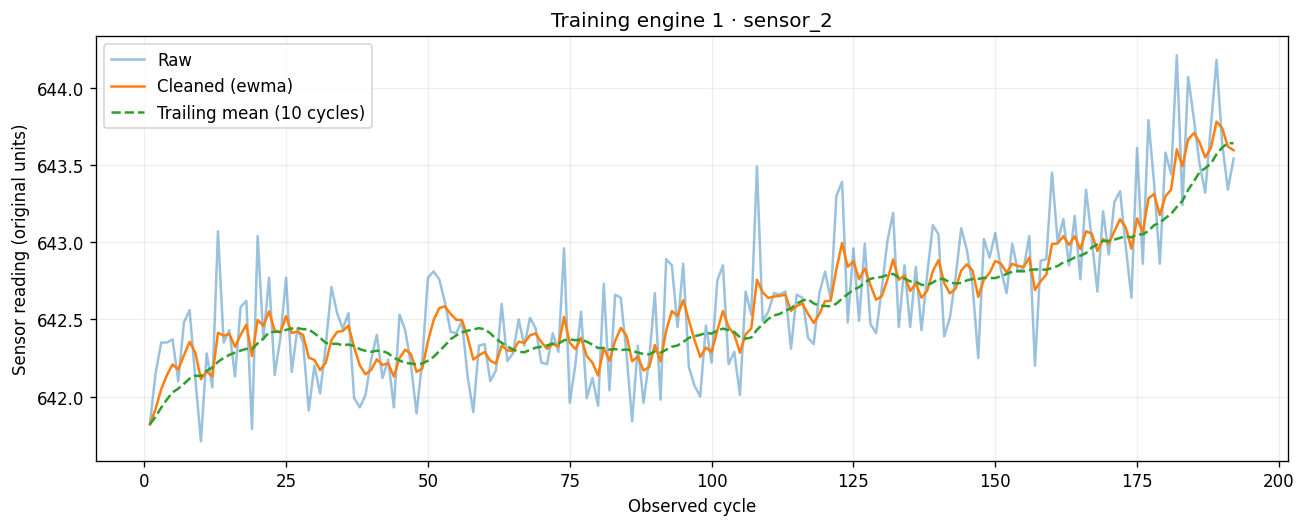

In [8]:
engine_clean = clean_train[clean_train.unit == engine_id].reset_index(drop=True)
engine_features = features[features.unit == engine_id].reset_index(drop=True)
mean, scale = processor.means[sensor], processor.scales[sensor]
cleaned_original_units = engine_clean[sensor] * scale + mean
rolling_original_units = engine_features[f"{sensor}_mean_{window}"] * scale + mean

fig, ax = plt.subplots()
ax.plot(raw_engine.cycle, raw_engine[sensor], label="Raw", alpha=0.45)
ax.plot(engine_clean.cycle, cleaned_original_units, label=f"Cleaned ({config['cleaning']['smoothing']})")
ax.plot(engine_features.cycle, rolling_original_units, label=f"Trailing mean ({window} cycles)", linestyle="--")
ax.set(title=f"Training engine {engine_id} · {sensor}", xlabel="Observed cycle",
       ylabel="Sensor reading (original units)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(plot_dir / "sensor_raw_cleaned_rolling.png")
plt.show()

## 9. Check that a future cycle cannot change earlier features

We build the same engine twice: once with its whole history and once with only
the first configured number of cycles. With the same frozen training settings,
the prefix features must match. This is a concrete test of **causality**.
It does not replace fold-level leakage checks: training-only statistics are
a separate requirement.

In [9]:
prefix_length = min(options["prefix_cycles"], len(raw_engine))
prefix = processor.transform(raw_engine.iloc[:prefix_length])
prefix_features = build_features(
    prefix, processor.sensor_columns,
    config["features"]["windows"], config["features"]["baseline_cycles"],
)
np.testing.assert_allclose(
    prefix_features[model_columns].to_numpy(),
    engine_features.iloc[:prefix_length][model_columns].to_numpy(),
)
print(f"PASS: the first {prefix_length} cycles match the full-history feature prefix.")

PASS: the first 20 cycles match the full-history feature prefix.


## 10. Create the correct training answers: RUL

Because training engines run to failure, an engine's last recorded cycle tells
us when its RUL reaches zero. Earlier RUL is `last_cycle - current_cycle`.
We cap that training target using the configured limit. The cap represents a
modeling assumption about healthy early life; it is not an engine safety limit.
Only targets use the engine's future failure cycle; the input features do not.

In [10]:
last_training_cycle = dataset.train.groupby("unit").cycle.transform("max")
targets = dataset.train[["unit", "cycle"]].copy()
targets["uncapped_rul"] = last_training_cycle - dataset.train.cycle
targets["capped_rul"] = capped_rul(dataset.train, config["target"]["rul_cap"])
engine_targets = targets[targets.unit == engine_id].reset_index(drop=True)
display(engine_targets.head(options["sample_rows"]))
display(engine_targets.tail(options["sample_rows"]))

,unit,cycle,uncapped_rul,capped_rul
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


,unit,cycle,uncapped_rul,capped_rul
187,1,188,4,4
188,1,189,3,3
189,1,190,2,2
190,1,191,1,1
191,1,192,0,0


## 11. Plot the RUL cap

The uncapped target falls by one cycle each cycle until failure. The capped
target stays flat during healthy early life, then follows the declining target.
This teaches the model a plateau followed by degradation. Test answers will
remain uncapped, so test engines with true RUL above the cap can still have error.

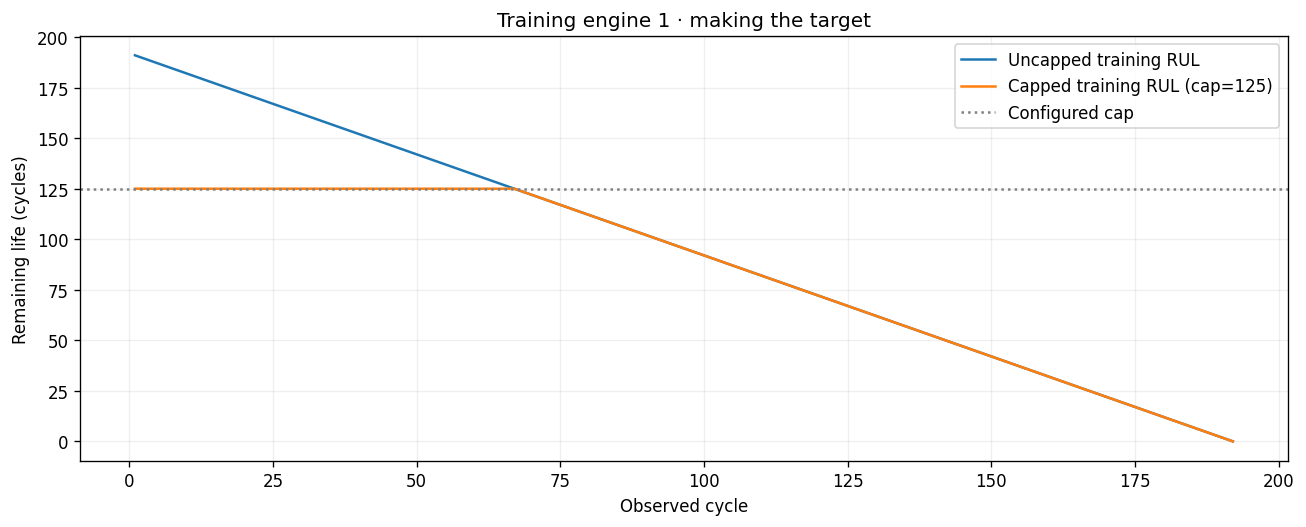

In [11]:
cap = config["target"]["rul_cap"]
fig, ax = plt.subplots()
ax.plot(engine_targets.cycle, engine_targets.uncapped_rul, label="Uncapped training RUL")
ax.plot(engine_targets.cycle, engine_targets.capped_rul, label=f"Capped training RUL (cap={cap})")
ax.axhline(cap, color="gray", linestyle=":", label="Configured cap")
ax.set(title=f"Training engine {engine_id} · making the target", xlabel="Observed cycle",
       ylabel="Remaining life (cycles)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(plot_dir / "rul_cap.png")
plt.show()

## 12. Split engines, not individual rows

Rows from one engine are related, so a random row split could put nearly identical
history into both training and validation. GroupKFold holds out entire engines.
The first fold below is one of the configured folds; its two lists of engine IDs
must not overlap. Shuffling the groups uses the fixed configured seed.

In [12]:
from src.models.rul import engine_folds, prepare_fold, make_model, bound_predictions
from src.models.evaluate import regression_metrics, last_cycle_evaluation

train_positions, validation_positions = next(engine_folds(dataset.train, config))
fold_train_raw = dataset.train.iloc[train_positions]
fold_validation_raw = dataset.train.iloc[validation_positions]
train_units = set(fold_train_raw.unit)
validation_units = set(fold_validation_raw.unit)
assert train_units.isdisjoint(validation_units)
display(pd.DataFrame([
    {"fold_part": "training", "engines": len(train_units), "rows": len(fold_train_raw)},
    {"fold_part": "validation", "engines": len(validation_units), "rows": len(fold_validation_raw)},
]).set_index("fold_part"))
print("Engine overlap:", train_units & validation_units)

,engines,rows
fold_part,,
training,80,16561
validation,20,4070


Engine overlap: set()


## 13. Refit preprocessing inside the fold

Grouping engines is not enough: validation engines must not influence scaling,
fill medians or sensor selection either. `prepare_fold()` fits a **new** processor
using only the fold's training engines. It then transforms both histories with
that state. We explicitly remove engine and cycle metadata from model inputs.

In [13]:
fold = prepare_fold(fold_train_raw, fold_validation_raw, config)
fold_columns = [column for column in fold.train.columns if column not in ["unit", "cycle"]]
assert not {"unit", "cycle", "rul", "true_rul"}.intersection(fold_columns)
print("Fold-local retained sensors:", fold.processor.sensor_columns)
print("Training input shape:", fold.train[fold_columns].shape)
print("Validation input shape:", fold.validation[fold_columns].shape)
print("Training-only median for the selected sensor:", fold.processor.medians[sensor])

Fold-local retained sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Training input shape: (16561, 154)
Validation input shape: (4070, 154)
Training-only median for the selected sensor: 642.64


## 14. Understand the three baseline models

Ridge learns a regularized linear relationship. RandomForest averages decision
trees, while LightGBM builds boosted trees that address previous errors. All
models receive the same fold's feature table and targets. Ridge uses a pipeline
that also scales engineered features using training rows only. The next cell
constructs the models but does not fit three large models just for this display.

In [14]:
display(pd.DataFrame([
    {"model": name, "Python estimator": type(make_model(name, config)).__name__,
     "configured parameters": config["training"][name]}
    for name in config["training"]["models"]
]))

,model,Python estimator,configured parameters
0,ridge,Pipeline,"{'alpha': 10.0, 'solver': 'cholesky'}"
1,random_forest,RandomForestRegressor,"{'n_estimators': 100, 'max_depth': 12, 'min_sa..."
2,lightgbm,LGBMRegressor,"{'n_estimators': 300, 'learning_rate': 0.05, '..."


## 15. Train a live Ridge example and validate it

`fit()` learns from the training feature table and its RUL answers.
`predict()` estimates RUL for held-out engines. We calculate error only after
predicting; validation answers never enter `fit()`. This quick live example
uses the first fold, not the pooled five-fold result. Predictions use the same
configured clipping policy as the main pipeline.

In [15]:
ridge = make_model("ridge", config)
with threadpool_limits(limits=config["training"]["n_jobs"]):
    ridge.fit(fold.train[fold_columns], fold.train_target)
    ridge_predictions = bound_predictions(ridge.predict(fold.validation[fold_columns]), config)
first_fold_metrics = regression_metrics(fold.validation_target, ridge_predictions)
display(pd.Series(first_fold_metrics, name="Live first-fold Ridge metrics").to_frame().round(3))

,Live first-fold Ridge metrics
rmse,15.432
mae,12.130
nasa_score,16814.396


## 16. Know how the complete Phase 2 training runs

The full pipeline repeats fold-local training for every model in all folds,
pools held-out predictions, selects the lowest configured validation error,
then refits each model on all training engines. Test scores are calculated only
after selection. We reuse the saved run by default so this walkthrough stays quick.

To repeat the full experiment, set `rerun_full_training: true` in
`configs/walkthrough.yaml` before running the notebook. It replaces the local
Phase 2 artifacts and previously took about 13 minutes with two CPU workers.
You can also run the command printed by the cell from the repo root.

In [16]:
from src.models.train import train_models

if options["rerun_full_training"]:
    train_models(config, subset, ROOT)
else:
    print("Reusing saved Phase 2 artifacts; full retraining is disabled in walkthrough.yaml.")
    print(r".\.venv\Scripts\python.exe run_pipeline.py --subset FD001 --stage train")

Reusing saved Phase 2 artifacts; full retraining is disabled in walkthrough.yaml.
.\.venv\Scripts\python.exe run_pipeline.py --subset FD001 --stage train


## 17. Load the experiment report and check its provenance

A report records model settings, metrics and input-file hashes. A hash is a
fingerprint of a file: matching hashes help confirm that the saved run used the
same data we are explaining. We also check the current pipeline settings against
the saved settings. If data or settings changed, rerun training before comparing
this notebook to the saved experiment. No result is invented when artifacts are missing.

In [17]:
report_dir = ROOT / config["paths"]["reports"] / subset
model_dir = ROOT / config["paths"]["models"] / subset
report_path = report_dir / "metrics.json"
if not report_path.is_file():
    raise FileNotFoundError("Phase 2 artifacts are missing. Run run_pipeline.py --subset FD001 --stage train.")
report = json.loads(report_path.read_text(encoding="utf-8"))
if report["config"] != config:
    raise ValueError("The saved experiment uses different settings; rerun Phase 2 with the current config.")
for filename, expected_hash in report["data_sha256"].items():
    actual_hash = hashlib.sha256((raw_dir / filename).read_bytes()).hexdigest()
    if actual_hash != expected_hash:
        raise ValueError(f"Data changed since training: {filename}. Rerun Phase 2.")
selected = report["selected_model"]
print("Saved run selected:", selected)
print("Selection metric:", report["selection_metric"])
print("Recorded seed:", report["seed"])
print("Input data fingerprints: all match")

Saved run selected: random_forest
Selection metric: rmse
Recorded seed: 42
Input data fingerprints: all match


## 18. Compare actual five-fold validation and test metrics

The validation metrics pool held-out predictions over **all training cycles**
with capped targets. Test metrics use **one last cycle per engine** with uncapped
official answers, so these populations differ. RMSE emphasizes large errors;
MAE is average absolute error; NASA score penalizes optimistic RUL errors more.
All three metrics are lower-is-better, and NASA totals depend on sample count.

In [18]:
comparison = pd.DataFrame([
    {"model": name,
     "CV RMSE": values["validation"]["rmse"], "CV MAE": values["validation"]["mae"],
     "CV NASA": values["validation"]["nasa_score"],
     "Test RMSE": values["test"]["rmse"], "Test MAE": values["test"]["mae"],
     "Test NASA": values["test"]["nasa_score"]}
    for name, values in report["experiments"].items()
]).set_index("model")
display(comparison.round(3))
print("Selected by validation, before test evaluation:", selected)

,CV RMSE,CV MAE,CV NASA,Test RMSE,Test MAE,Test NASA
model,,,,,,
ridge,15.614,12.042,81508.085,16.184,13.041,390.200
random_forest,11.737,7.900,47893.345,13.398,9.939,261.450
lightgbm,11.896,7.821,50083.508,14.520,11.185,299.863


Selected by validation, before test evaluation: random_forest


## 19. Inspect the saved folds and reproduce the live example

The audit file lists training/validation engines and preprocessing state for
every fold. We check that the engine sets are disjoint and that every training
engine was held out exactly once. We also compare our live Ridge example with
the saved first-fold Ridge metrics. This connects the small demonstration to
the actual five-fold run rather than showing unrelated results.

In [19]:
audits = json.loads((report_dir / "fold_audit.json").read_text(encoding="utf-8"))
held_out_units = []
for audit in audits:
    assert set(audit["train_units"]).isdisjoint(audit["validation_units"])
    held_out_units.extend(audit["validation_units"])
assert sorted(held_out_units) == sorted(dataset.train.unit.unique().tolist())
assert audits[0]["preprocessor"] == fold.processor.state()
saved_fold_metrics = pd.read_csv(report_dir / "fold_metrics.csv")
saved_first_ridge = saved_fold_metrics[
    (saved_fold_metrics.model == "ridge") & (saved_fold_metrics.fold == audits[0]["fold"])
].iloc[0]
for metric, value in first_fold_metrics.items():
    np.testing.assert_allclose(value, saved_first_ridge[metric])
print("PASS: engine folds and first-fold Ridge results match the saved run.")

PASS: engine folds and first-fold Ridge results match the saved run.


## 20. Reload the selected model and predict test histories

The saved bundle includes the fitted model, sensor preprocessing, exact feature
order and config. We load the locally generated file and call `predict()` on
the real test histories. Test answers are not supplied to prediction. The bundle
processes each engine's complete observed history from cycle 1; it is not yet a
stateful one-row streaming service.

In [20]:
import joblib

predictor = joblib.load(model_dir / f"{selected}.joblib")
assert predictor.model_name == selected
assert not {"unit", "cycle", "rul", "true_rul"}.intersection(predictor.feature_columns)
with threadpool_limits(limits=config["training"]["n_jobs"]):
    test_predictions = predictor.predict(dataset.test)
display(test_predictions.head(options["sample_rows"]))
print("Observed test cycles predicted:", len(test_predictions))

,unit,cycle,predicted_rul
0,1,1,124.466986
1,1,2,124.299172
2,1,3,124.232285
3,1,4,123.979208
4,1,5,124.150913


Observed test cycles predicted: 13096


## 21. Evaluate only the last observed cycle of each test engine

NASA supplies one answer per test engine, at its final observed cycle. Joining
those answers to earlier rows would be wrong. We select the last cycle and join
by engine ID, not by an accidental row order. Official answers remain uncapped.
The printed metrics are recomputed from fresh model predictions and checked
against the saved report, not copied into the code as constants.

In [21]:
test_last = last_cycle_evaluation(test_predictions, dataset.test_rul)
test_metrics = regression_metrics(test_last.true_rul.to_numpy(), test_last.predicted_rul.to_numpy())
assert len(test_last) == dataset.test.unit.nunique()
np.testing.assert_array_equal(
    test_last.cycle.to_numpy(), dataset.test.groupby("unit").cycle.max().to_numpy()
)
for metric, value in test_metrics.items():
    np.testing.assert_allclose(value, report["experiments"][selected]["test"][metric])
display(test_last.head(options["sample_rows"]))
display(pd.Series(test_metrics, name=f"Recomputed {selected} test metrics").to_frame().round(3))
print("Official test truth range:", test_last.true_rul.min(), "to", test_last.true_rul.max())

,unit,cycle,predicted_rul,true_rul
0,1,31,122.286929,112
1,2,49,122.711314,98
2,3,126,60.762695,69
3,4,106,81.189023,82
4,5,98,87.196556,91


,Recomputed random_forest test metrics
rmse,13.398
mae,9.939
nasa_score,261.450


Official test truth range: 7 to 145


## 22. Plot predicted versus true RUL for test engines

Each dot represents one test engine at its last observed cycle. The dashed ideal
line means prediction equals truth. Points above that line overestimate remaining
life; points below it underestimate remaining life. The axes use cycles, and the
model was selected using validation results rather than this chart.

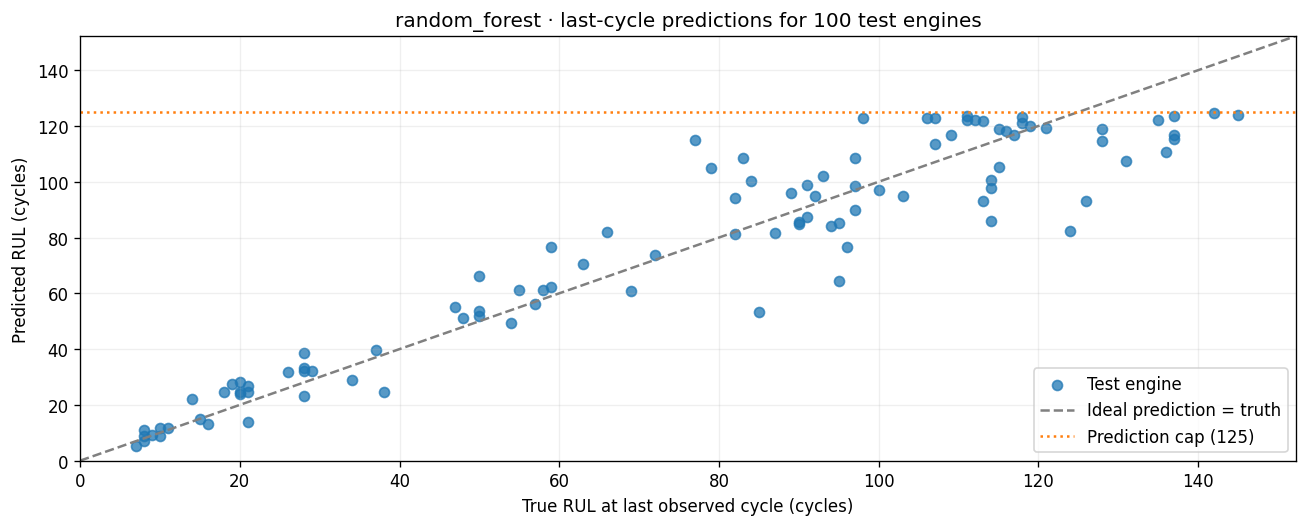

In [22]:
fig, ax = plt.subplots()
ax.scatter(test_last.true_rul, test_last.predicted_rul, alpha=0.75, label="Test engine")
upper = max(test_last.true_rul.max(), test_last.predicted_rul.max(), cap)
upper = upper * (1 + options["scatter_padding_fraction"])
ax.plot([0, upper], [0, upper], color="gray", linestyle="--", label="Ideal prediction = truth")
if config["training"]["clip_predictions"]:
    ax.axhline(cap, color="tab:orange", linestyle=":", label=f"Prediction cap ({cap})")
ax.set(xlim=(0, upper), ylim=(0, upper),
       title=f"{selected} · last-cycle predictions for {len(test_last)} test engines",
       xlabel="True RUL at last observed cycle (cycles)", ylabel="Predicted RUL (cycles)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(plot_dir / "predicted_vs_true_rul.png")
plt.show()

## 23. Plot the error histogram

We define error as **predicted RUL minus true RUL**. Zero is perfect. Positive
errors are optimistic (the engine has less life than predicted), while negative
errors are conservative. Each histogram bin counts test engines in an error
range; the bin count is a presentation setting. The NASA score assigns stronger
penalties to the positive side for equal-sized errors.

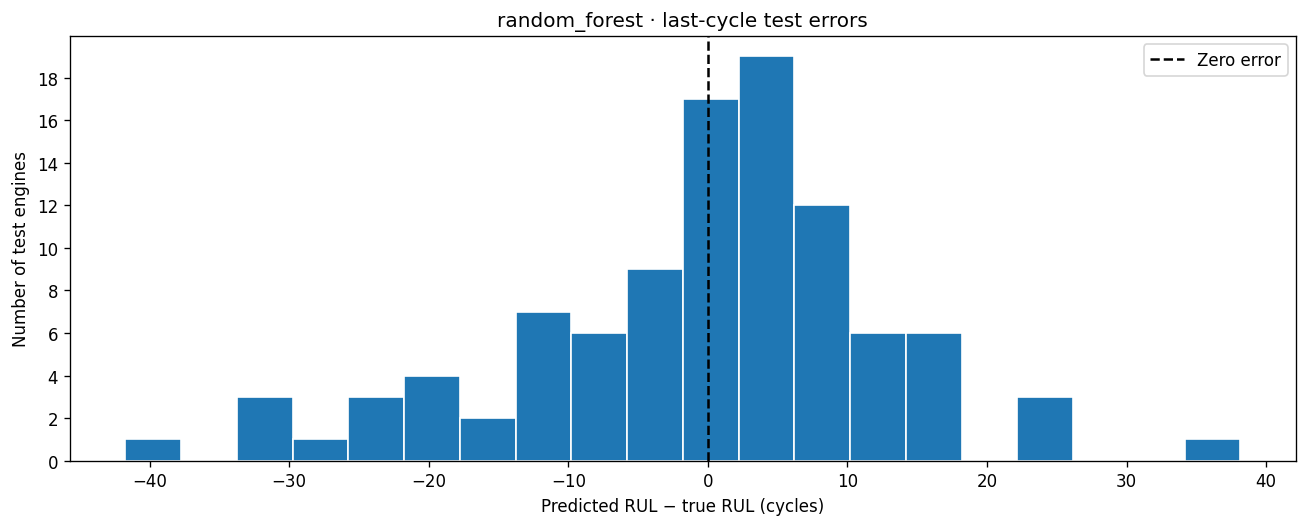

In [23]:
test_last["error"] = test_last.predicted_rul - test_last.true_rul
fig, ax = plt.subplots()
ax.hist(test_last.error, bins=options["histogram_bins"], color="tab:blue", edgecolor="white")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.axvline(0, color="black", linestyle="--", label="Zero error")
ax.set(title=f"{selected} · last-cycle test errors", xlabel="Predicted RUL − true RUL (cycles)",
       ylabel="Number of test engines")
ax.legend()
fig.tight_layout()
fig.savefig(plot_dir / "error_histogram.png")
plt.show()

## 24. Inspect errors without tuning to the test answers

The average signed error shows overall optimism or conservatism; it is different
from MAE, which ignores signs. The rows below show the largest optimistic errors.
They are useful for understanding limitations, but we do not change the model
based on these test cases and then claim the same test score is an unbiased
evaluation. A RUL estimate is not a fault diagnosis or a maintenance guarantee.

In [24]:
display(pd.Series({
    "mean_signed_error": test_last.error.mean(),
    "smallest_signed_error": test_last.error.min(),
    "largest_signed_error": test_last.error.max(),
    "mean_absolute_error": test_last.error.abs().mean(),
}, name="Error summary (cycles)").to_frame().round(3))
display(test_last.sort_values("error", ascending=False).head(options["sample_rows"]).round(3))
print("Plot exports:", plot_dir)

,Error summary (cycles)
mean_signed_error,-0.698
smallest_signed_error,-41.732
largest_signed_error,38.139
mean_absolute_error,9.939


,unit,cycle,predicted_rul,true_rul,error
66,67,71,115.139,77,38.139
49,50,74,105.083,79,26.083
14,15,76,108.524,83,25.524
1,2,49,122.711,98,24.711
97,98,121,76.439,59,17.439


Plot exports: C:\Users\Asus\Documents\self-healing-machines\artifacts\notebooks\FD001


## What you should now be able to explain

You loaded real engine histories, separated inputs from answers, cleaned each
engine causally, built trailing features, created capped training targets,
validated on held-out engines with fold-local preprocessing, and evaluated a
saved model at each test engine's last observed cycle. The four plots illustrate
those choices using actual readings and predictions.

The full experiment report, data fingerprints and notebook checks keep the
numbers connected to a real run. The notebook's optional training switch is off
by default; the live Ridge example still demonstrates actual fitting.

**Current scope:** FD001 preprocessing and RUL prediction only. Anomaly detection,
near-failure classification, maintenance rules/work orders, MLflow, drift monitoring
and the dashboard are planned later phases. More operating conditions and real
operational validation remain limitations.

For presentation practice, read `VIVA.md` in the repo root. For code choices see
`DESIGN.md`, and for commands see `README.md`. To re-execute this entire notebook
and save its inline outputs, run from the repo root:

```powershell
.\.venv\Scripts\python.exe scripts/execute_walkthrough.py
```

No new phase is started by this walkthrough.